# HD 137010 b – eccentric orbits

The paper assumes $e=0$. Here we replace this by priors on $e$ and look at period, orbit and HZ.

- Same chord speed, different period: $P = G\rho_*\,g^3/(3\pi v^3)$ with $g=(1+e\sin\omega)/\sqrt{1-e^2}$.
- Transiting planets are biased to eccentric orbits near periastron: factor $(1+e\sin\omega)/(1-e^2)$.
- Periastron $a(1-e) > 2R_*$ (≈ Roche limit), $\omega\sim U(0,2\pi)$, period prior $\alpha=-1$ ($P^{-8/3}$) unless stated.

| | $e$ prior | motivation |
|---|---|---|
| M0 | $e=0$ | paper |
| M3 | Rayleigh($\sigma=0.049$) | small planets in multis (Van Eylen et al. 2019) |
| M4 | Rayleigh, mean $e=0.15$ | upper limit on mean $e$ of temperate Earth-sized planets (Kipping et al. 2025, cited in the paper) |
| M2 | Beta(0.867, 3.03) | RV planets (Kipping 2013) |
| M1 | $U(0,1)$ | no information |

Method: the shape fit from 03 (Sec. 5), reweighted with $p(\ln P)\,p_{\rm tr}(e,\omega)$. On an eccentric orbit
the star–planet distance changes slightly during the transit, so the weights also include
$L_{\rm exact}/L_{\rm shape}$ with the full eccentric `batman` likelihood – the reweighting is then exact.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import transit as tr

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
t, f, P_MIN = tr.load_data()
REF = "loguniform_kipping"                     # alpha = -1
ALPHAS = {"kipping": r"$\alpha=0$", "uniform_a_kipping": r"$\alpha=-2/3$", "loguniform_kipping": r"$\alpha=-1$"}
MODELS = {"M0": "circular", "M3": "rayleigh_vaneylen19", "M4": "rayleigh_mean015",
          "M2": "beta_kipping13", "M1": "uniform"}
LABEL = {"M0": "M0: e = 0", "M3": "M3: Rayleigh 0.049", "M4": "M4: mean e = 0.15",
         "M2": "M2: Beta", "M1": "M1: uniform"}

sh = np.load("results/shape.npz")
ch = sh["chain"][sh["chain"].shape[0] // 2:]           # drop burn-in half
post = ch.reshape(-1, ch.shape[-1])[::20]
N_DRAWS = 20                                           # prior draws (rho*, e, w) per shape sample

def wquantile(x, w, q):
    i = np.argsort(x)
    c = np.cumsum(w[i])
    return np.interp(q, c / c[-1], x[i])

def summ(x, w, fmt="{:.0f}"):
    lo, med, hi = wquantile(x, w, [0.15865, 0.5, 0.84135])
    return f"{fmt.format(med)} -{fmt.format(med - lo)} +{fmt.format(hi - med)}"

def pareto_khat(w):
    # PSIS diagnostic (Vehtari et al. 2015): tail shape of the largest weights, k < 0.7 is fine
    w = np.sort(w)[::-1]
    m = int(min(0.2 * len(w), 3 * np.sqrt(len(w))))
    return stats.genpareto.fit(w[:m] - w[m], floc=0)[0]

def hz(I, w, lim):
    return np.sum(w[(I > lim[0]) & (I < lim[1])])

print(f"{len(post)} shape samples x {N_DRAWS} prior draws")

16250 shape samples x 20 prior draws


/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/.venv/lib/python3.13/site-packages/batman/tests.py:107: SyntaxWarning: invalid escape sequence '\ '
  )   \     /   (
/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/.venv/lib/python3.13/site-packages/batman/tests.py:119: SyntaxWarning: invalid escape sequence '\/'
  /_ \/ |__


## 1. Reweighting

One pass per $e$ prior with the exact likelihood (cached in `results/`); the other $\alpha$ only change the
weights by a power of $P$. The evidence $Z$ needs only the prior normalisation $C$ (docstring of
`shape_to_physical`).

In [2]:
def reweighted(e_prior):
    fn = Path(f"results/reweighted_{e_prior}.npz")
    if not fn.exists():
        th, e, om, w, lnz = tr.shape_to_physical(post, REF, e_prior, p_min=P_MIN, n_draws=N_DRAWS, rng=0,
                                                 return_lnz=True, data=None if e_prior == "circular" else (t, f))
        k = w > 0
        np.savez_compressed(fn, theta=th[k], e=e[k], om=om[k], w=w[k], lnz=lnz)
    r = np.load(fn)
    return {k: r[k] for k in r.files}

lnC = {(a, e): tr.log_prior_norm(a, e, P_MIN, tr.P_MAX, rng=1) for a in ALPHAS for e in MODELS.values()}

R = {}
for m, e_prior in MODELS.items():
    r = reweighted(e_prior)
    for a in ALPHAS:
        lw = np.log(r["w"]) + (tr.PERIOD_PRIORS[a] - tr.PERIOD_PRIORS[REF]) * r["theta"][:, 1]
        mx = lw.max()
        w = np.exp(lw - mx)
        lnz = r["lnz"] + mx + np.log(w.sum()) - lnC[a, e_prior] + lnC[REF, e_prior]
        R[m, a] = dict(theta=r["theta"], e=r["e"], om=r["om"], w=w / w.sum(), lnz=float(lnz),
                       d=tr.derived(r["theta"], rng=2, e=r["e"]))

dz = {a: np.load(f"results/dynesty_{a}.npz") for a in ["kipping", REF]}
print(f"ln B(alpha=0 vs -1), e=0: reweighting {R['M0', 'kipping']['lnz'] - R['M0', REF]['lnz']:.2f}, "
      f"dynesty {float(dz['kipping']['logz'] - dz[REF]['logz']):.2f} "
      f"± {np.hypot(float(dz['kipping']['logzerr']), float(dz[REF]['logzerr'])):.2f}")

/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/ian/transit.py:343: UserWarning: 2 draws (max e = 0.9795, weight 3.9e-05) kept the shape approximation
  warnings.warn(f"{len(failed)} draws (max e = {e[failed].max():.4f}, weight {frac:.1e}) "


ln B(alpha=0 vs -1), e=0: reweighting 1.03, dynesty 0.80 ± 0.22


## 2. What do the data say about $e$?

Black: prior on $e$ for transiting planets (with period prior and periastron cut). Filled: posterior.
Information gain = KL divergence posterior ‖ prior.

,prior e median,posterior e median,posterior e 95%,KL [bits]
model,,,,
M3: Rayleigh 0.049,0.058,0.058,0.121,0.000
M4: mean e = 0.15,0.143,0.149,0.310,0.005
M2: Beta,0.204,0.232,0.622,0.037
M1: uniform,0.836,0.511,0.927,0.555


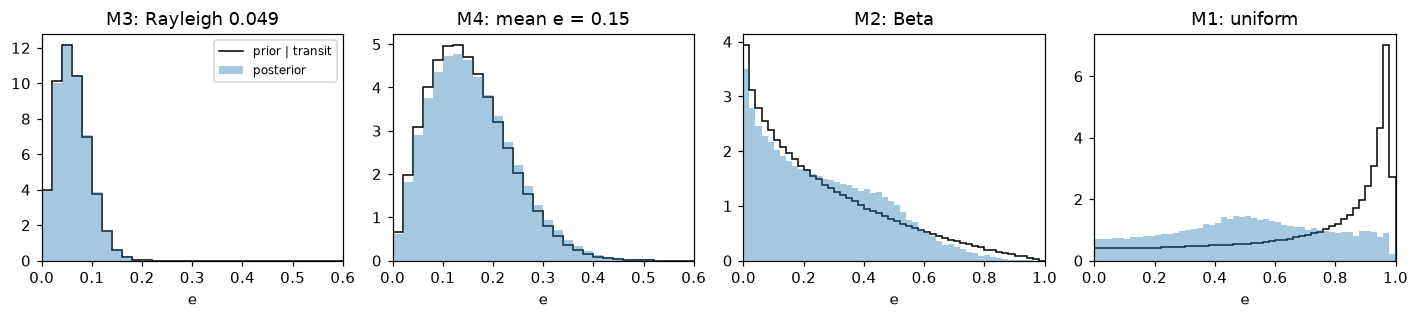

In [3]:
rng = np.random.default_rng(5)
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
bins = np.linspace(0, 1, 51)
rows = []
for ax, m in zip(axes, ["M3", "M4", "M2", "M1"]):
    n = 2_000_000
    e0, om0 = tr.draw_e_w(MODELS[m], n, rng)
    lnP0 = rng.uniform(np.log(P_MIN), np.log(tr.P_MAX), n)
    lw0 = tr.log_orbit_weight(np.exp(lnP0), e0, om0, rng.normal(*tr.LOG_RHO_PRIOR, n), REF, P_MIN, tr.P_MAX)
    pw = np.exp(lw0 - lw0.max())
    hp, _ = np.histogram(e0, bins, weights=pw, density=True)
    r = R[m, REF]
    hq, _ = np.histogram(r["e"], bins, weights=r["w"], density=True)
    ax.stairs(hp, bins, color="k", label="prior | transit")
    ax.stairs(hq, bins, fill=True, alpha=0.4, label="posterior")
    ax.set(title=LABEL[m], xlabel="e", xlim=(0, 1 if m in ("M1", "M2") else 0.6))
    ok = (hq > 0) & (hp > 0)
    rows.append({"model": LABEL[m], "prior e median": wquantile(e0, pw, 0.5),
                 "posterior e median": wquantile(r["e"], r["w"], 0.5),
                 "posterior e 95%": wquantile(r["e"], r["w"], 0.95),
                 "KL [bits]": np.sum(hq[ok] * np.log2(hq[ok] / hp[ok])) * np.diff(bins)[0]})
axes[0].legend(fontsize=8)
fig.tight_layout()
display(pd.DataFrame(rows).set_index("model").round(3))

## 3. Period, orbit and HZ ($\alpha=-1$)

HZ limits from the paper (Sec. 4.2): conservative 0.30–1.00, optimistic 0.27–1.60 $I_\oplus$.
Orbit-averaged insolation $\langle I\rangle = L/(a^2\sqrt{1-e^2})$.

In [4]:
def row(m, a):
    r = R[m, a]; d, w = r["d"], r["w"]
    return {"P [d]": summ(d["P"], w), "Pr(P<200 d)": np.sum(w[d["P"] < 200]),
            "a [AU]": summ(d["a_au"], w, "{:.2f}"), "I [I_earth]": summ(d["insolation"], w, "{:.2f}"),
            "Pr(HZ cons.)": hz(d["insolation"], w, tr.HZ_CONSERVATIVE),
            "Pr(HZ opt.)": hz(d["insolation"], w, tr.HZ_OPTIMISTIC),
            "Pr(hotter than HZ)": np.sum(w[d["insolation"] > tr.HZ_OPTIMISTIC[1]]),
            "ln B vs M0": r["lnz"] - R["M0", a]["lnz"],
            "ESS": 1 / np.sum(w**2), "k-hat": pareto_khat(w)}

display(pd.DataFrame({LABEL[m]: row(m, REF) for m in MODELS}).T.round(3))

,P [d],Pr(P<200 d),a [AU],I [I_earth],Pr(HZ cons.),Pr(HZ opt.),Pr(hotter than HZ),ln B vs M0,ESS,k-hat
M0: e = 0,345 -54 +146,0.000038,0.87 -0.09 +0.23,0.31 -0.12 +0.09,0.521255,0.635602,0.0,0.0,215345.567242,-0.025318
M3: Rayleigh 0.049,344 -74 +153,0.007209,0.86 -0.13 +0.24,0.31 -0.12 +0.13,0.528451,0.628196,0.0,0.011846,207059.000218,-0.007349
M4: mean e = 0.15,311 -111 +202,0.156628,0.81 -0.21 +0.32,0.36 -0.17 +0.30,0.565924,0.662366,0.007374,0.075363,166995.65719,0.081466
M2: Beta,269 -154 +203,0.352234,0.73 -0.32 +0.33,0.44 -0.24 +1.06,0.44661,0.600021,0.147232,0.116896,104657.620346,-0.053794
M1: uniform,156 -74 +238,0.601813,0.51 -0.18 +0.44,1.13 -0.84 +1.91,0.299589,0.460744,0.394972,-0.535231,47912.277617,0.530593


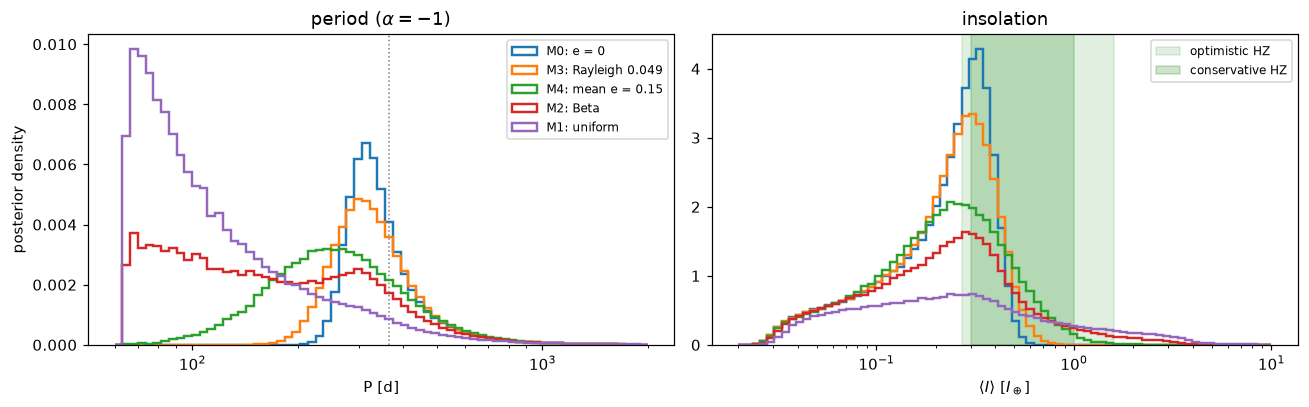

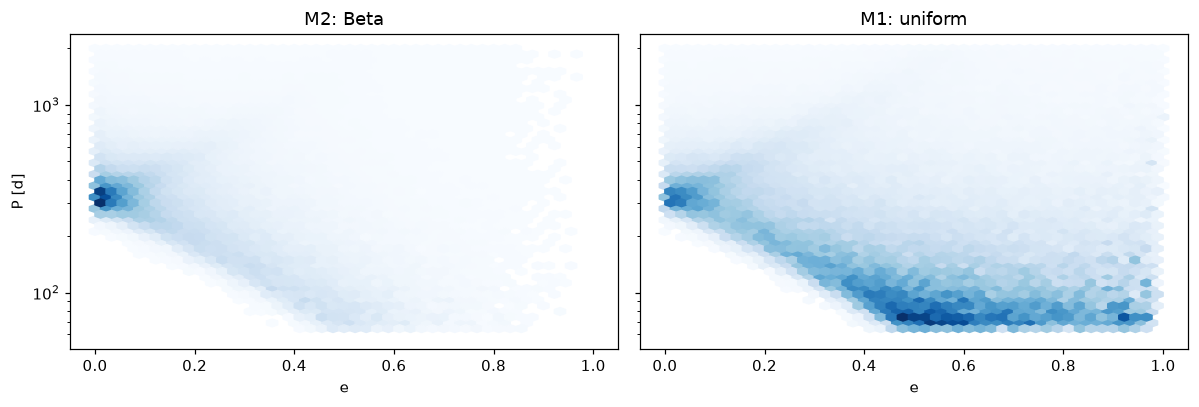

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for m in MODELS:
    r = R[m, REF]
    axes[0].hist(r["d"]["P"], bins=np.geomspace(60, 2000, 70), weights=r["w"], density=True,
                 histtype="step", lw=1.6, label=LABEL[m])
    axes[1].hist(r["d"]["insolation"], bins=np.geomspace(0.02, 10, 75), weights=r["w"], density=True,
                 histtype="step", lw=1.6)
axes[0].axvline(365.25, color="gray", ls=":", lw=1)
axes[0].set(xscale="log", xlabel="P [d]", ylabel="posterior density", title=r"period ($\alpha=-1$)")
axes[0].legend(fontsize=8)
axes[1].axvspan(*tr.HZ_OPTIMISTIC, color="g", alpha=0.12, label="optimistic HZ")
axes[1].axvspan(*tr.HZ_CONSERVATIVE, color="g", alpha=0.2, label="conservative HZ")
axes[1].set(xscale="log", xlabel=r"$\langle I\rangle$ [$I_\oplus$]", title="insolation")
axes[1].legend(fontsize=8)
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, m in zip(axes, ["M2", "M1"]):
    r = R[m, REF]
    ax.hexbin(r["e"], r["d"]["P"], C=r["w"], reduce_C_function=np.sum, gridsize=45, yscale="log",
              cmap="Blues", mincnt=1, extent=(0, 1, np.log10(60), np.log10(2000)))
    ax.set(xlabel="e", title=LABEL[m])
axes[0].set_ylabel("P [d]")
fig.tight_layout()

## 4. The paper's argument for $e=0$

The paper: for $e\lesssim0.2$ the extra period uncertainty is not larger than the one from $b$. With
$\ln P = \ln P_{\rm circ}(v,\rho_*) + 3\ln g$ we split the width of $\ln P$:

In [6]:
rows = []
for m in MODELS:
    r = R[m, REF]; w = r["w"]
    lnP = r["theta"][:, 1]
    lng3 = 3 * np.log(tr.g_factor(r["e"], r["om"]))
    hw = lambda x: (wquantile(x, w, 0.84135) - wquantile(x, w, 0.15865)) / 2
    rows.append({"model": LABEL[m], "68% half-width ln P": hw(lnP), "from P_circ (b, rho*)": hw(lnP - lng3),
                 "from 3 ln g (e, w)": hw(lng3), "Pr(e > 0.2)": np.sum(w[r["e"] > 0.2])})
display(pd.DataFrame(rows).set_index("model").round(3))

,68% half-width ln P,"from P_circ (b, rho*)","from 3 ln g (e, w)",Pr(e > 0.2)
model,,,,
M0: e = 0,0.262,0.262,0.000,0.000
M3: Rayleigh 0.049,0.306,0.262,0.148,0.000
M4: mean e = 0.15,0.469,0.262,0.367,0.287
M2: Beta,0.705,0.279,0.636,0.552
M1: uniform,0.788,0.366,0.819,0.852


## 5. Period prior × eccentricity prior

In [7]:
grid = {}
for a, al in ALPHAS.items():
    for m in MODELS:
        r = R[m, a]; d, w = r["d"], r["w"]
        grid[al, m] = {"P median [d]": wquantile(d["P"], w, 0.5), "Pr(P<200 d)": np.sum(w[d["P"] < 200]),
                       "Pr(HZ cons.)": hz(d["insolation"], w, tr.HZ_CONSERVATIVE),
                       "ln Z (rel. M0, alpha=-1)": r["lnz"] - R["M0", REF]["lnz"]}
g = pd.DataFrame(grid).T
for col in g.columns:
    print(col)
    display(g[col].unstack()[list(MODELS)].round(0 if "P median" in col else 2))

P median [d]


,M0,M3,M4,M2,M1
$\alpha=-1$,345.0,344.0,311.0,269.0,156.0
$\alpha=-2/3$,354.0,356.0,336.0,305.0,203.0
$\alpha=0$,378.0,388.0,399.0,385.0,353.0


Pr(P<200 d)


,M0,M3,M4,M2,M1
$\alpha=-1$,0.0,0.01,0.16,0.35,0.60
$\alpha=-2/3$,0.0,0.01,0.12,0.27,0.49
$\alpha=0$,0.0,0.00,0.07,0.14,0.27


Pr(HZ cons.)


,M0,M3,M4,M2,M1
$\alpha=-1$,0.52,0.53,0.57,0.45,0.30
$\alpha=-2/3$,0.48,0.48,0.51,0.44,0.32
$\alpha=0$,0.40,0.39,0.39,0.36,0.32


ln Z (rel. M0, alpha=-1)


,M0,M3,M4,M2,M1
$\alpha=-1$,0.00,0.01,0.08,0.12,-0.54
$\alpha=-2/3$,0.38,0.39,0.41,0.38,-0.40
$\alpha=0$,1.03,1.02,1.01,0.90,-0.07


## 6. Checks

Three ways to the same posterior ($\alpha=-1$):
- emcee shape fit + reweighting (above),
- dynesty shape fit + reweighting (`run_dynesty.py --shape`): other sampler, and absolute evidences,
- dynesty on the full eccentric model in $(P, b, \rho_*, e, \omega, \dots)$ (`run_dynesty.py --e-prior`); its
  evidence is normalised with the same $C$.

For M0 also the authors' chain.

/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/ian/transit.py:343: UserWarning: 3 draws (max e = 0.9822, weight 1.6e-04) kept the shape approximation
  warnings.warn(f"{len(failed)} draws (max e = {e[failed].max():.4f}, weight {frac:.1e}) "


/Users/ian/Documents/ETH/HS26/BayStat/hd137010b-bayes/ian/transit.py:367: RuntimeWarning: invalid value encountered in arccos
  inc = np.arccos(b / aR)


P [d]  Pr(P<200 d)  e median  \
model             method                                                 
M0: e = 0         emcee shape      345 -54 +146        0.000     0.000   
                  dynesty shape    350 -57 +165        0.000     0.000   
                  dynesty direct   347 -54 +150        0.000     0.000   
                  authors          355 -59 +190        0.000     0.000   
M4: mean e = 0.15 emcee shape     311 -111 +202        0.157     0.149   
                  dynesty shape   317 -114 +212        0.150     0.149   
                  dynesty direct  302 -111 +203        0.184     0.152   
M2: Beta          emcee shape     269 -154 +203        0.352     0.232   
                  dynesty shape   273 -155 +213        0.346     0.232   
                  dynesty direct  247 -131 +184        0.384     0.232   
M1: uniform       emcee shape      156 -74 +238        0.602     0.511   
                  dynesty shape    156 -75 +242        0.600     0.516   
                  dynesty direct   123 -46 +167        0.701     0.600   

                                  Pr(b<0.3)  Pr(HZ cons.)      ln Z  
model             method                                             
M0: e = 0         emcee shape         0.555         0.521       NaN  
                  dynesty shape       0.523         0.497  1224.610  
                  dynesty direct      0.560         0.511  1224.680  
                  authors             0.511         0.478       NaN  
M4: mean e = 0.15 emcee shape         0.555         0.566       NaN  
                  dynesty shape       0.524         0.551  1224.685  
                  dynesty direct      0.540         0.573  1224.322  
M2: Beta          emcee shape         0.532         0.447       NaN  
                  dynesty shape       0.500         0.441  1224.729  
                  dynesty direct      0.526         0.487  1224.729  
M1: uniform       emcee shape         0.465         0.300       NaN  
                  dynesty shape       0.434         0.297  1224.090  
                  dynesty direct      0.513         0.266  1224.083

ln Z errors: dynesty shape ± 0.16, dynesty direct ± ~0.15


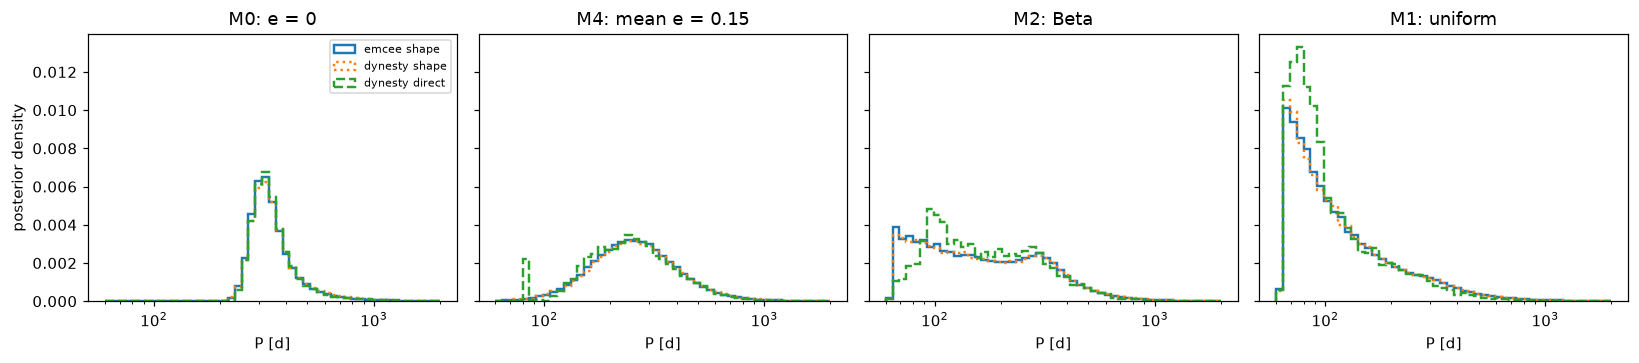

In [8]:
dsh = np.load("results/dynesty_shape.npz")
S = dsh["samples"][np.random.default_rng(0).choice(len(dsh["samples"]), len(post), replace=False)]
x = tr.PERIOD_PRIORS[REF]
au = pd.read_csv("posteriors.csv", index_col=0)
a_au = (tr.G * au.M.values * tr.MSUN * (au.P.values * tr.DAY) ** 2 / (4 * np.pi**2)) ** (1 / 3) / tr.AU
I_au = np.random.default_rng(3).normal(*tr.LUM, len(au)) / a_au**2

rows, hists = [], {}
for m in ["M0", "M4", "M2", "M1"]:
    ep = MODELS[m]
    dy = np.load(f"results/dynesty_{REF}" + ("" if ep == "circular" else f"_{ep}") + ".npz")
    s = dy["samples"]
    e_dy = np.zeros(len(s)) if ep == "circular" else s[:, 10]
    lnz_dy = float(dy["logz"]) + (0 if ep == "circular" else np.log((tr.P_MAX**x - P_MIN**x) / x) - lnC[REF, ep])
    th, e2, _, w2, lnz2 = tr.shape_to_physical(S, REF, ep, p_min=P_MIN, n_draws=N_DRAWS, rng=0, return_lnz=True,
                                               data=None if ep == "circular" else (t, f))
    r = R[m, REF]
    methods = [("emcee shape", r["d"], r["w"], r["e"], r["theta"][:, 2], np.nan),
               ("dynesty shape", tr.derived(th, rng=2, e=e2), w2, e2, th[:, 2], float(dsh["logz"]) + lnz2),
               ("dynesty direct", tr.derived(s[:, :10], rng=2, e=e_dy), np.full(len(s), 1 / len(s)), e_dy, s[:, 2], lnz_dy)]
    if m == "M0":
        methods.append(("authors", {"P": au.P.values, "insolation": I_au}, np.full(len(au), 1 / len(au)),
                        np.zeros(len(au)), au.b.values, np.nan))
    for lab, d, w, e, b, lnz in methods:
        rows.append({"model": LABEL[m], "method": lab, "P [d]": summ(d["P"], w),
                     "Pr(P<200 d)": np.sum(w[d["P"] < 200]), "e median": wquantile(e, w, 0.5),
                     "Pr(b<0.3)": np.sum(w[b < 0.3]), "Pr(HZ cons.)": hz(d["insolation"], w, tr.HZ_CONSERVATIVE),
                     "ln Z": lnz})
        hists[m, lab] = (d["P"], w)
display(pd.DataFrame(rows).set_index(["model", "method"]).round(3))
print(f"ln Z errors: dynesty shape ± {float(dsh['logzerr']):.2f}, dynesty direct ± ~0.15")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, m in zip(axes, ["M0", "M4", "M2", "M1"]):
    for lab, ls in [("emcee shape", "-"), ("dynesty shape", ":"), ("dynesty direct", "--")]:
        P, w = hists[m, lab]
        ax.hist(P, bins=np.geomspace(60, 2000, 50), weights=w, density=True, histtype="step", lw=1.6, ls=ls, label=lab)
    ax.set(xscale="log", xlabel="P [d]", title=LABEL[m])
axes[0].set_ylabel("posterior density")
axes[0].legend(fontsize=7)
fig.tight_layout()

## Conclusions

$\alpha=-1$ (Sec. 3):

| model | $P$ [d] | $\Pr(P<200\,{\rm d})$ | $\langle I\rangle$ [$I_\oplus$] | HZ cons. / opt. | hotter than HZ |
|---|---|---|---|---|---|
| M0 $e=0$ | 345 −54 +146 | 0 | 0.31 −0.12 +0.09 | 52 % / 64 % | 0 |
| M3 Rayleigh 0.049 | 344 −74 +153 | 1 % | 0.31 −0.12 +0.13 | 53 % / 63 % | 0 |
| M4 mean $e=0.15$ | 311 −111 +202 | 16 % | 0.36 −0.17 +0.30 | 57 % / 66 % | 1 % |
| M2 Beta | 269 −154 +203 | 35 % | 0.44 −0.24 +1.06 | 45 % / 60 % | 15 % |
| M1 uniform | 156 −74 +238 | 60 % | 1.1 −0.8 +1.9 | 30 % / 46 % | 39 % |

- One transit says almost nothing about $e$: for M3, M4, M2 the posterior of $e$ is the prior
  (KL ≤ 0.04 bits). The assumed $e$ prior comes straight back out, and the period with it.
- The paper's argument holds only for nearly circular orbits. For M3 the $e$ part of the $\ln P$ width is 0.15
  vs 0.26 from $b,\rho_*$. For M4 – the prior that matches the paper's own citation – it is 0.37, already larger
  than the $b$ part: $P = 311^{+202}_{-111}$ d, 16 % at $P<200$ d.
- HZ probability stays at 45–57 % (conservative) except for uniform $e$ (30 %), but the failure direction
  changes: at $e=0$ every non-HZ solution is too cold, with Beta 15 % and uniform 39 % are too hot. "Near the
  outer edge of the HZ" is a consequence of $e=0$.
- The data can't choose: all $|\ln B|\le0.6$ between $e$ priors (Sec. 3, 5).
- Period prior and $e$ prior add up: with $\alpha=0$ the short-period solutions are suppressed
  ($\Pr(P<200)$ = 14 % Beta, 27 % uniform). For M2/M1 the posterior piles up at $P_{\min}=64$ d, so it is
  limited by the K2 window, not by the transit.
- HZ fractions from the authors' samples with the paper's limits: 48 % / 59 %; the paper text says 40 % / 51 %.
  Not reproducible with any definition we tried (fixed or uncertain $L$, $L$ from $R_*$ and $T_{\rm eff}$,
  limits in flux, period or distance) – would need ≈ 6 % lower insolation. Ask the authors.

Checks (Sec. 1, 6): exact eccentric likelihood in the weights; $\hat k\le0.53$, ESS ≥ 4.8×10⁴; emcee and
dynesty in shape space agree for all models; reweighting evidences agree with direct nested sampling
($\Delta\ln Z\lesssim0.4$). For $e=0$ the direct dynesty posterior also agrees. For broad $e$ priors the direct
dynesty run puts more weight at short periods ($\Pr(P<200)$ 0.38 vs 0.35 Beta, 0.70 vs 0.60 uniform) – taken as
the systematic uncertainty of these numbers.

Open: correlated noise (02b), the exact Kipping et al. (2025) $e$ distribution (M4 is only the widest one allowed
by their limit).